In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler

import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid")

In [ ]:
data = pd.read_csv('/content/Salary_dataset.csv')
data.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


1. Data Preprocessing (data.shape, data.column)

In [ ]:
data.columns

Index(['Unnamed: 0', 'YearsExperience', 'Salary'], dtype='object')

In [ ]:
data.shape

(30, 3)

2. Check and Handle Missing Values

In [ ]:
data.isnull().sum()

,0
Unnamed: 0,0
YearsExperience,0
Salary,0


In [ ]:
data.drop(columns=['Unnamed: 0'], inplace=True)
data

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0
5,3.0,56643.0
6,3.1,60151.0
7,3.3,54446.0
8,3.3,64446.0
9,3.8,57190.0


In [ ]:
data.head()

,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0


3. Check and Handle Outliers

In [ ]:
def check_outliers(column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[(data[column] < lower_limit) | (data[column] > upper_limit)]

    print(f"\nOutliers in '{column}':")
    print(outliers)
    return outliers

check_outliers("Salary")
check_outliers("YearsExperience")


Outliers in 'Salary':
Empty DataFrame
Columns: [YearsExperience, Salary]
Index: []

Outliers in 'YearsExperience':
Empty DataFrame
Columns: [YearsExperience, Salary]
Index: []


,YearsExperience,Salary


4. Bivariate Analysis (Years of Exp. against Salary )- Line Plot

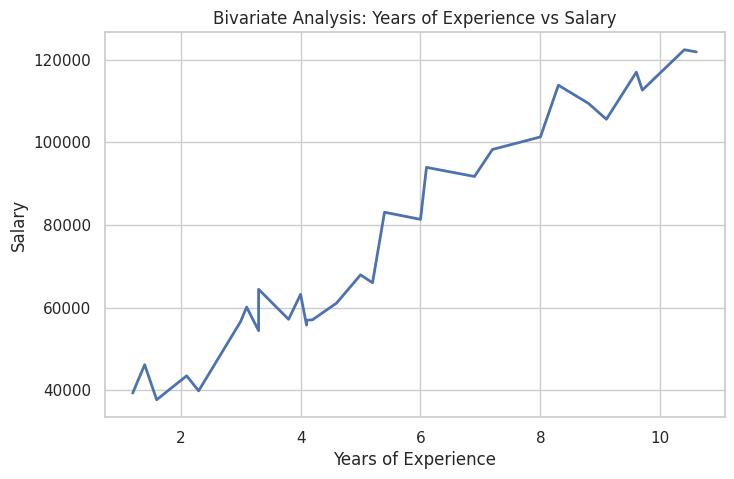

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(data["YearsExperience"], data["Salary"], linewidth=2)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Bivariate Analysis: Years of Experience vs Salary")
plt.grid(True)

plt.show()

5. Scaling (Years of experience)

In [ ]:
scaler = MinMaxScaler()
data["YearsExperience_MinMax"] = scaler.fit_transform(data[["YearsExperience"]])

print(data[["YearsExperience", "YearsExperience_MinMax"]].head())

   YearsExperience  YearsExperience_MinMax
0              1.2                0.000000
1              1.4                0.021277
2              1.6                0.042553
3              2.1                0.095745
4              2.3                0.117021


6. Log (Salary)

In [ ]:
data["Log_Salary"] = np.log(data["Salary"])

print(data[["Salary", "Log_Salary"]].head())

    Salary  Log_Salary
0  39344.0   10.580099
1  46206.0   10.740865
2  37732.0   10.538264
3  43526.0   10.681114
4  39892.0   10.593931


7. Train test split

In [ ]:
X = data[["YearsExperience"]]
y = data["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (24, 1)
Testing data shape: (6, 1)


8. Train and evaluate Linear and SGD Regressor Model

In [ ]:

from sklearn.pipeline import Pipeline

model_lr = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

# Train model
model_lr.fit(X_train, y_train)

# Predictions
y_pred_train_lr = model_lr.predict(X_train)
y_pred_test_lr = model_lr.predict(X_test)

# RMSE
rmse_train_lr = np.sqrt(mean_squared_error(y_train, y_pred_train_lr))
rmse_test_lr = np.sqrt(mean_squared_error(y_test, y_pred_test_lr))

print("==== Linear Regression Results ====")
print(f"Train RMSE: {rmse_train_lr:.2f}")
print(f"Test RMSE: {rmse_test_lr:.2f}")

# Overfitting / underfitting check
difference_lr = rmse_test_lr - rmse_train_lr
threshold_lr = rmse_train_lr * 0.10
if difference_lr > threshold_lr:
    print("Model likely overfitting (test error much higher than train).")
elif difference_lr < -threshold_lr:
    print("Model might be underfitting (train error unusually high). Check preprocessing.")
else:
    print("Model seems to generalize well (train/test errors close).")


# SGD Regressor Pipeline

model_sgd = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('regressor', SGDRegressor(max_iter=1000, learning_rate='optimal', eta0=0.01, random_state=42))
])

# Train model
model_sgd.fit(X_train, y_train)

# Predictions
y_pred_train_sgd = model_sgd.predict(X_train)
y_pred_test_sgd = model_sgd.predict(X_test)

# RMSE
rmse_train_sgd = np.sqrt(mean_squared_error(y_train, y_pred_train_sgd))
rmse_test_sgd = np.sqrt(mean_squared_error(y_test, y_pred_test_sgd))

print("\n==== SGD Regressor Results ====")
print(f"Train RMSE: {rmse_train_sgd:.2f}")
print(f"Test RMSE: {rmse_test_sgd:.2f}")

# Overfitting / underfitting check
difference_sgd = rmse_test_sgd - rmse_train_sgd
threshold_sgd = rmse_train_sgd * 0.10
if difference_sgd > threshold_sgd:
    print("Model likely overfitting (test error much higher than train).")
elif difference_sgd < -threshold_sgd:
    print("Model might be underfitting (train error unusually high). Check preprocessing.")
else:
    print("Model seems to generalize well (train/test errors close).")


==== Linear Regression Results ====
Train RMSE: 5205.98
Test RMSE: 7059.04
Model likely overfitting (test error much higher than train).

==== SGD Regressor Results ====
Train RMSE: 13264964991850.08
Test RMSE: 13635325774707.87
Model seems to generalize well (train/test errors close).
